# Pre-Entrega 6 — Demostración del flujo de delegación

Orquestador multi-agente de análisis técnico Volkswagen, con topología **jerárquica**: un **Supervisor** que
delega en un **Investigador** y un **Analista**, un **Validador** determinístico como puerta de calidad y una
**Síntesis** final.

Esta notebook muestra:
1. El grafo.
2. Una delegación completa: Supervisor → Investigador → Analista → Síntesis.
3. El camino de fallo: un especialista falla y el supervisor no se rompe.
4. El bucle de reparación y el escalado a revisión humana.

**Requisitos:** el `.env` configurado (por ejemplo `LLM_PROVIDER=openai` y `OPENAI_API_KEY`). La notebook hace
unas 35 llamadas al LLM: con `gpt-4o-mini`, unos pocos centavos de dólar.

In [ ]:
from IPython.display import Image, Markdown, display

from graph import crear_orquestador
from llm import describir_llm
from prompts import PROMPTS_VERSION, huella_prompts
from traza import correr_tarea

app = crear_orquestador()
print(f"LLM: {describir_llm()} | prompts {PROMPTS_VERSION} ({huella_prompts()})")

2026-10-12 17:27:36.035 | INFO     | llm:get_llm:82 - LLM: openai / gpt-4o-mini (temperature=0.0)


LLM: openai / gpt-4o-mini | prompts v1 (ba30becc)


## 1. El grafo

Generado con `draw_mermaid_png()` a partir del grafo compilado.

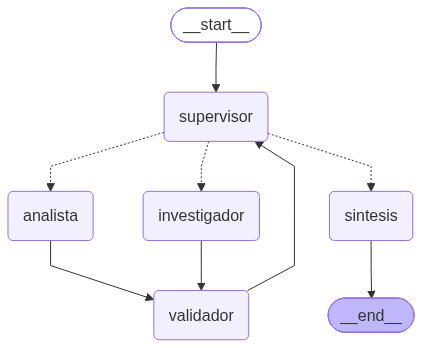

In [ ]:
try:
    display(Image(app.get_graph().draw_mermaid_png()))
except Exception as error:  # draw_mermaid_png usa un servicio web: sin internet, se muestra el texto
    print(f"(PNG no disponible: {error})")
    print(app.get_graph().draw_mermaid())

In [ ]:
def tabla_de_decisiones(corrida) -> None:
    """Quién decidió qué y por qué: el registro del supervisor, paso a paso."""
    filas = ["| Paso | Origen | Decisión | Por qué |", "|---|---|---|---|"]
    for d in corrida.estado_final["decisiones"]:
        filas.append(f"| {d.paso} | {d.origen} | {d.siguiente} | {d.razon} |")
    display(Markdown("\n".join(filas)))

## 2. Delegación completa

La pregunta requiere dos dominios: **datos** (el Investigador consulta el catálogo) y **cálculo** (el Analista
resta y suma), y una **síntesis** final.

Respuesta esperada: **49 CV, 80 Nm y 3 unidades**.

In [ ]:
corrida = await correr_tarea(
    app,
    "¿Cuántos CV y cuántos Nm más tiene el Virtus Exclusive que el Tera High, y cuántas unidades "
    "de esas dos versiones hay en total en la sucursal Palermo?",
)

👤 Usuario: "¿Cuántos CV y cuántos Nm más tiene el Virtus Exclusive que el Tera High, y cuántas unidades de esas dos versiones hay en total en la sucursal Palermo?"
🧭 Supervisor [llm] → investigador
     por qué: Faltan datos sobre la potencia, torque y stock de las versiones solicitadas para poder realizar el análisis.
     instrucción: Buscar los datos de potencia (CV) y torque (Nm) del modelo Virtus Exclusive y del modelo Tera High. Además, buscar el stock total de unidades de ambas versiones en la sucursal Palermo.
🔎 Investigador (3.6s): Se encontraron los datos de potencia y torque del modelo Virtus Exclusive y del modelo Tera High, así como el stock total de unidades en la sucursal Palermo.
     · potencia del Virtus Exclusive = 150 CV  [fuente: catalogo_concesionaria]
     · torque del Virtus Exclusive = 250 Nm  [fuente: catalogo_concesionaria]
     · potencia del Tera High = 101 CV  [fuente: catalogo_concesionaria]
     · torque del Tera High = 170 Nm  [fuente: catalogo_concesio

In [ ]:
tabla_de_decisiones(corrida)

| Paso | Origen | Decisión | Por qué |
|---|---|---|---|
| 0 | llm | investigador | Faltan datos sobre la potencia, torque y stock de las versiones solicitadas para poder realizar el análisis. |
| 1 | llm | analista | Se han validado todos los datos necesarios, y ahora se requiere un análisis de las diferencias y el total de unidades. |
| 2 | llm | FINALIZAR | Se ha completado la tarea con todos los datos validados y el análisis realizado correctamente. |

## 3. Camino de fallo: un especialista falla

Se simula que el Investigador lanza un error en su primer intento (`fallar_investigador`). El supervisor no se
rompe: el Validador registra el fallo y una **regla** del supervisor lo reintenta.

Respuesta esperada: **80 Nm**.

In [ ]:
corrida_fallo = await correr_tarea(
    app,
    "¿Cuánto torque más tiene el Taos que el Nivus Sense?",
    simulacion={"fallar_investigador": 1},
)

👤 Usuario: "¿Cuánto torque más tiene el Taos que el Nivus Sense?"
   (simulación de fallos activada: {'fallar_investigador': 1})
🧭 Supervisor [llm] → investigador
     por qué: Faltan datos sobre el torque de los modelos Taos y Nivus Sense para poder realizar el cálculo solicitado.
     instrucción: Buscar los datos de torque del modelo Taos y del modelo Nivus Sense en el catálogo de la concesionaria y en las fichas técnicas. Devuelve el torque de cada modelo con su fuente.
🔎 Investigador ❌ falló (0.0s): RuntimeError: Fallo simulado del investigador (prueba del camino de error)
🛡️ Validador: ❌ el aporte del investigador NO pasó la validación
     - RuntimeError: Fallo simulado del investigador (prueba del camino de error)
🧭 Supervisor [regla] → investigador
     por qué: El investigador falló al ejecutarse: se reintenta (1/2).
     instrucción: Tu intento anterior falló por un error técnico: RuntimeError: Fallo simulado del investigador (prueba del camino de error) Volvé a intentarlo. 

In [ ]:
tabla_de_decisiones(corrida_fallo)

| Paso | Origen | Decisión | Por qué |
|---|---|---|---|
| 0 | llm | investigador | Faltan datos sobre el torque de los modelos Taos y Nivus Sense para poder realizar el cálculo solicitado. |
| 1 | regla | investigador | El investigador falló al ejecutarse: se reintenta (1/2). |
| 2 | llm | analista | Se han validado los datos de torque de ambos modelos, y ahora se necesita realizar el cálculo de la diferencia. |
| 3 | llm | FINALIZAR | Se ha completado la tarea: se han validado todos los datos necesarios y se ha realizado el análisis correspondiente. |

## 4. Bucle de reparación y escalado a revisión humana

Se simula que el Analista se equivoca **siempre** en la cuenta (`corromper_analisis`). El Validador lo detecta
recalculando con código, el supervisor le devuelve el error específico (bucle de reparación) y, después de
`MAX_REPARACIONES` intentos, **escala a revisión humana** en vez de reintentar sin fin.

La respuesta final tiene que avisar que el resultado requiere revisión humana.

In [ ]:
corrida_escalado = await correr_tarea(
    app,
    "¿Cuántas unidades de la Saveiro hay en total, sumando todas sus versiones, en la sucursal Córdoba?",
    simulacion={"corromper_analisis": 99},
)

👤 Usuario: "¿Cuántas unidades de la Saveiro hay en total, sumando todas sus versiones, en la sucursal Córdoba?"
   (simulación de fallos activada: {'corromper_analisis': 99})
🧭 Supervisor [llm] → investigador
     por qué: Faltan datos sobre el stock de la Saveiro en la sucursal Córdoba.
     instrucción: Buscar el total de unidades de la Volkswagen Saveiro en la sucursal Córdoba, sumando todas sus versiones. Proporcionar la fuente de los datos obtenidos.
🔎 Investigador (2.4s): Se encontraron tres versiones de la Volkswagen Saveiro en la sucursal Córdoba, con un total de 8 unidades disponibles.
     · stock de Saveiro Trendline cabina simple en Córdoba = 4 unidades  [fuente: catalogo_concesionaria]
     · stock de Saveiro Comfortline cabina doble en Córdoba = 2 unidades  [fuente: catalogo_concesionaria]
     · stock de Saveiro Extreme cabina doble en Córdoba = 2 unidades  [fuente: catalogo_concesionaria]
🛡️ Validador: ✅ el aporte del investigador pasó la validación
🧭 Supervisor [llm] →

In [ ]:
tabla_de_decisiones(corrida_escalado)
print("Escalado a revisión humana:", corrida_escalado.estado_final["escalado_humano"])

| Paso | Origen | Decisión | Por qué |
|---|---|---|---|
| 0 | llm | investigador | Faltan datos sobre el stock de la Saveiro en la sucursal Córdoba. |
| 1 | llm | analista | Se necesita realizar un cálculo para obtener el total de unidades de la Saveiro en Córdoba, ya que la investigación ha sido validada y no hay análisis realizado aún. |
| 2 | regla | analista | Bucle de reparación (1/2): se reenvía al analista su output con los errores específicos del validador, no un reintento ciego. |
| 3 | regla | analista | Bucle de reparación (2/2): se reenvía al analista su output con los errores específicos del validador, no un reintento ciego. |
| 4 | regla | FINALIZAR | El analista no pasó la validación después de 2 reparaciones: se escala a revisión humana en vez de seguir reintentando (evita el bucle infinito de corrección). |

Escalado a revisión humana: True


## Conclusión

- El **Supervisor** decide con dos capas: **reglas determinísticas** (límites, reparación, escalado) y el
  **LLM** con su rúbrica para todo lo demás. Cada decisión queda registrada con su origen y su razón.
- Ningún dato llega a la respuesta final sin pasar por el **Validador**, que verifica con código de dónde sale
  cada número y recalcula cada cuenta.
- Los especialistas reciben solo su instrucción puntual, y cada uno escribe únicamente en su parcela del estado.